In [ ]:
#bussiness probelm statement
'''automobile manufacture and automotive analysis want to understand
how vehicales characteristics such as horsepower,engine volume,speed
and weight inluence fuel efficiency(MPG)'''

'''fuel efficiency is a critical factor affecting customer
purchase decision and weight influence, regulatory compilence
and environment impact'''

#bussiness objective
'''identify key factors affecting fuel efficiency
quantify the relationship bet MPG and vehicle specification
build predictive model to estimate'''

#motiation
'''Understanding factors affecting mpg helps

Design fuel efficient vehicles
Reduce fuel consumption and emission
Improve competitive positioning in the automobile market
Support environmentally sustainable transportation
Helps customers to make informed purchasing decision'''


#Constraints
'''Strong multi collinerity exist between some variable
Real world vehicle performance maybe affected by additional factors
Linear regression assumptions may not fully hold
Outliers and extreme vehicles may influence model accuracy
Dataset size maybe limited'''


#success  criteria
'''Business success criteria is
Ability to identify key factors affecting fuel efficiency
Provide actionable insights for the vehicle design optimisation
Support decision making for automotive engineering and planning'''

#Machine learning success criteria
'''High r squared values strong explintary power
Statistically significant predictors p value less than 0.05
Low prediction error RMSE
Residual approximately normal distributed
Minimal multi collinerity after feature selection'''




'High r squared values strong explintary power\nStatistically significant predictors p value less than 0.05\nLow prediction error RMSE\nResidual approximately normal distributed\nMinimal multi collinerity after feature selection'

In [ ]:
!pip install statsmodels
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [ ]:
cars=pd.read_csv("/content/Cars.csv")
print("first 5 rows:\n",cars.head())
print("data types:\n",cars.dtypes)
print("summary stat:\n",cars.describe())
print("missing val:\n",cars.isnull().sum())
print("mean:\n",cars.mean(numeric_only=True))

first 5 rows:
    HP        MPG  VOL          SP         WT
0  49  53.700681   89  104.185353  28.762059
1  55  50.013401   92  105.461264  30.466833
2  55  50.013401   92  105.461264  30.193597
3  70  45.696322   92  113.461264  30.632114
4  53  50.504232   92  104.461264  29.889149
data types:
 HP       int64
MPG    float64
VOL      int64
SP     float64
WT     float64
dtype: object
summary stat:
                HP        MPG         VOL          SP         WT
count   81.000000  81.000000   81.000000   81.000000  81.000000
mean   117.469136  34.422076   98.765432  121.540272  32.412577
std     57.113502   9.131445   22.301497   14.181432   7.492813
min     49.000000  12.101263   50.000000   99.564907  15.712859
25%     84.000000  27.856252   89.000000  113.829145  29.591768
50%    100.000000  35.152727  101.000000  118.208698  32.734518
75%    140.000000  39.531633  113.000000  126.404312  37.392524
max    322.000000  53.700681  160.000000  169.598513  52.997752
missing val:
 HP     0

In [ ]:
print("variance:\n",cars.var())
print("standard deviation:\n",cars.std())
print("skewness:\n",cars.skew())

variance:
 HP     3261.952160
MPG      83.383283
VOL     497.356790
SP      201.113002
WT       56.142247
dtype: float64
standard deviation:
 HP     57.113502
MPG     9.131445
VOL    22.301497
SP     14.181432
WT      7.492813
dtype: float64
skewness:
 HP     1.716216
MPG   -0.177947
VOL   -0.590197
SP     1.611450
WT    -0.614753
dtype: float64


In [ ]:
print("kurtosis:\n",cars.kurtosis())

kurtosis:
 HP     2.960025
MPG   -0.611679
VOL    0.920229
SP     2.977329
WT     0.950291
dtype: float64


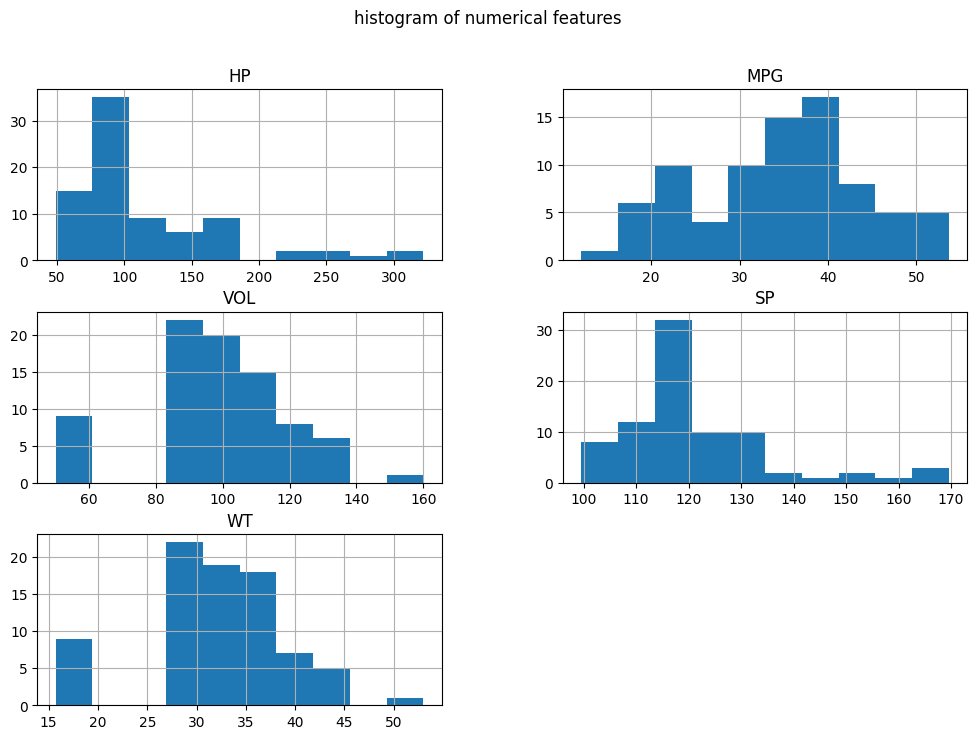

In [ ]:
cars.hist(figsize=(12,8))
plt.suptitle("histogram of numerical features")
plt.show()

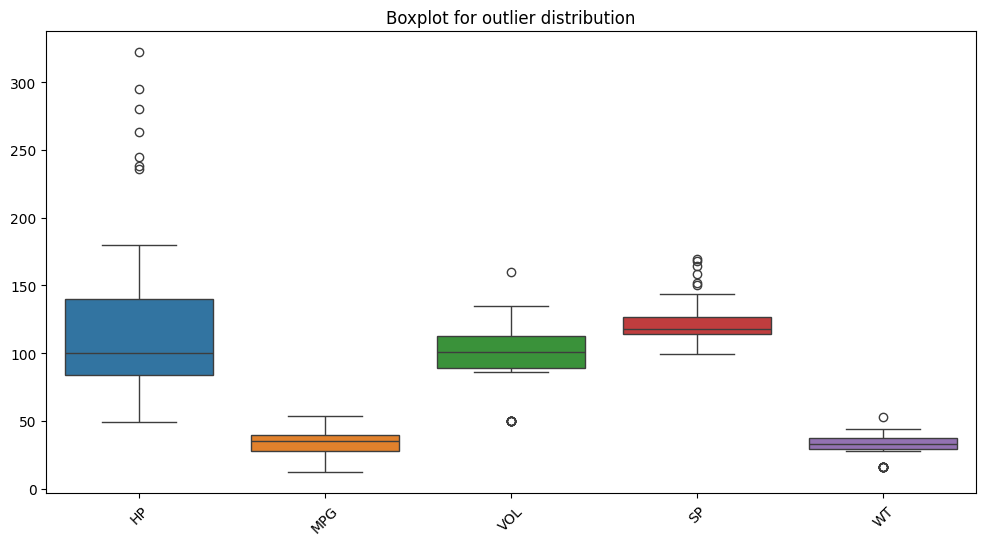

In [ ]:
plt.figure(figsize=(12,6))
sns.boxplot(data=cars)
plt.xticks(rotation=45)
plt.title("Boxplot for outlier distribution")
plt.show()

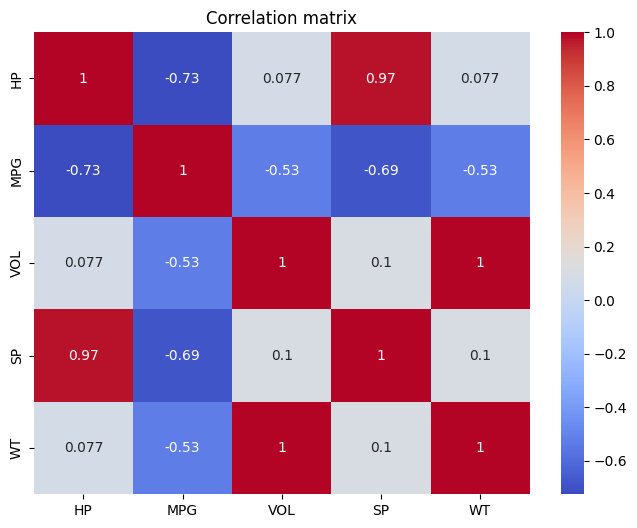

In [ ]:
#correlation matrix
plt.figure(figsize=(8,6))
sns.heatmap(cars.corr(),annot=True,cmap="coolwarm")
plt.title("Correlation matrix")
plt.show()

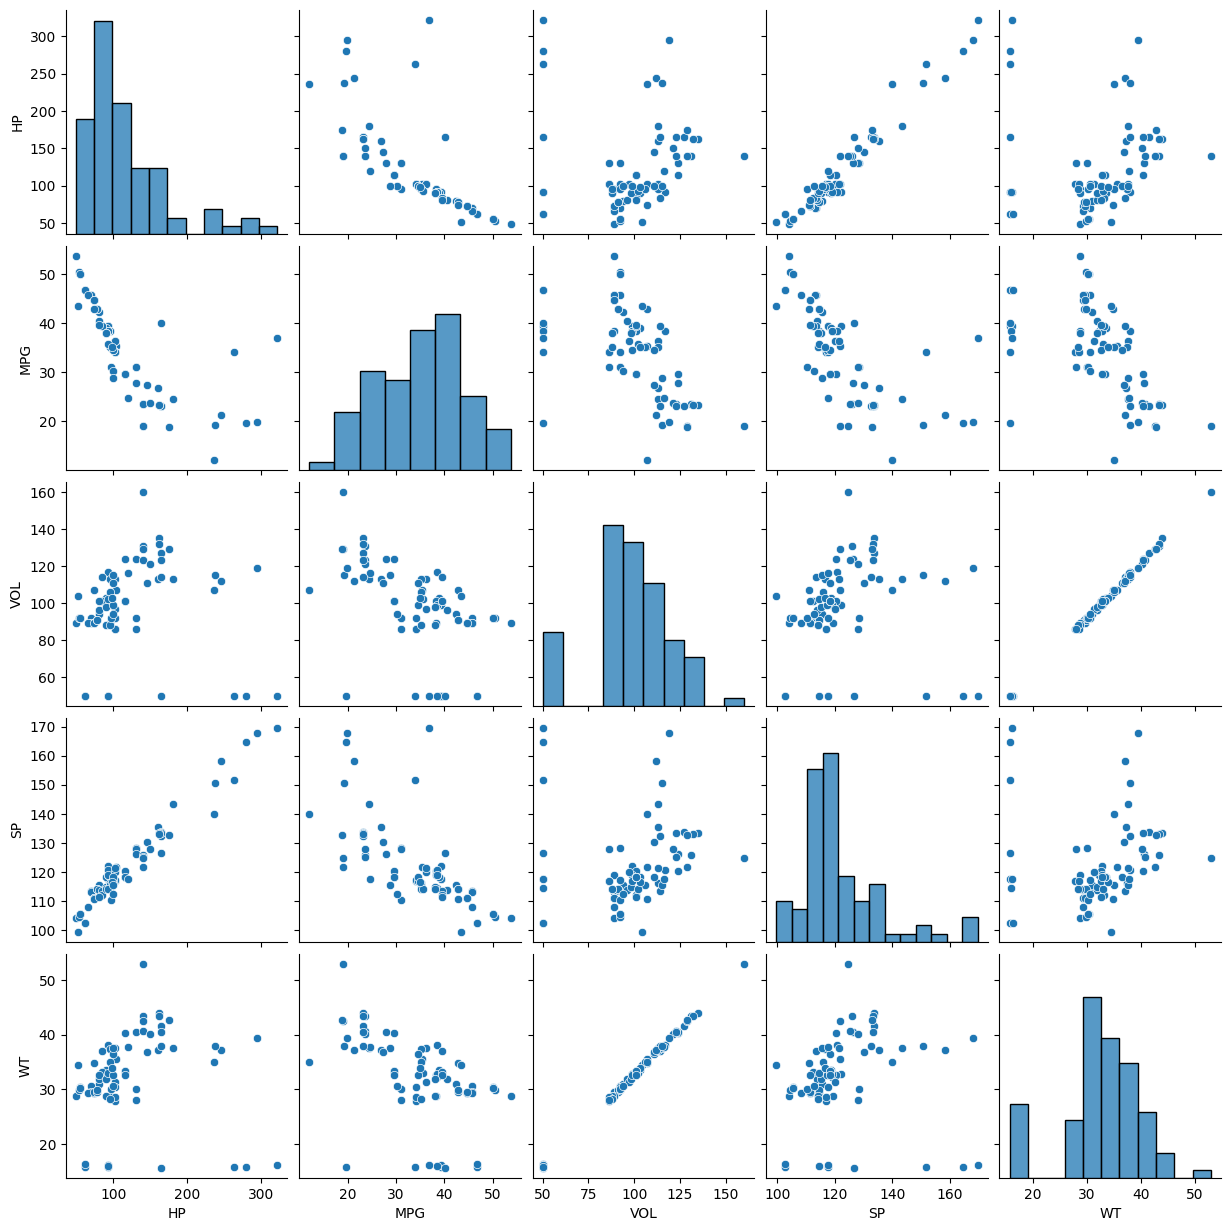

In [ ]:
sns.pairplot(cars)
plt.show()

In [ ]:
#assuming milage is dependant variable
x=cars
x_const=sm.add_constant(x)

In [ ]:
vif_data=pd.DataFrame()
vif_data["feature"]=x_const.columns
vif_data["VIF"]=[variance_inflation_factor(x_const.values,i)
for i in range(x_const.shape[1])]
print("varience inflation factor:\n",vif_data)

varience inflation factor:
   feature         VIF
0   const  942.710300
1      HP   27.122274
2     MPG    4.358006
3     VOL  641.741616
4      SP   21.652846
5      WT  640.004648


In [ ]:
import statsmodels.api as sm
import scipy.stats as stats
import matplotlib.pyplot as plt

y=cars["MPG"]
x=cars.drop(columns=["MPG"])
x=sm.add_constant(x)
model=sm.OLS(y,x).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                    MPG   R-squared:                       0.771
Model:                            OLS   Adj. R-squared:                  0.758
Method:                 Least Squares   F-statistic:                     63.80
Date:                Thu, 04 Jun 2026   Prob (F-statistic):           1.54e-23
Time:                        11:32:58   Log-Likelihood:                -233.96
No. Observations:                  81   AIC:                             477.9
Df Residuals:                      76   BIC:                             489.9
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         30.6773     14.900      2.059      0.0

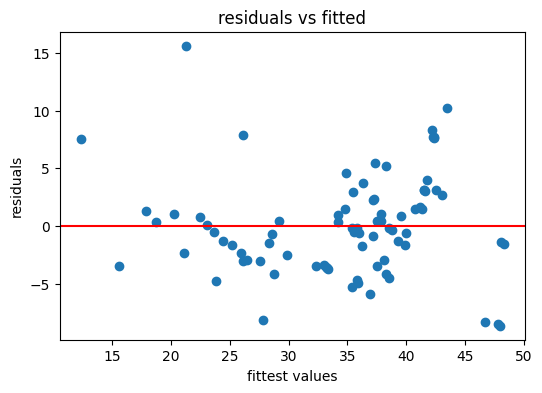

In [ ]:
residuals=model.resid
fitted_vals=model.fittedvalues

plt.figure(figsize=(6,4))
plt.scatter(fitted_vals,residuals)
plt.axhline(0,color='red')
plt.xlabel("fittest values")
plt.ylabel("residuals")
plt.title("residuals vs fitted")
plt.show()

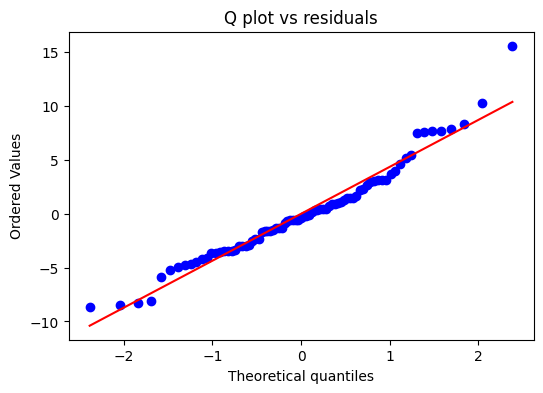

In [ ]:
plt.figure(figsize=(6,4))
stats.probplot(residuals,dist="norm",plot=plt)
plt.title("Q plot vs residuals")
plt.show()

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from scipy.stats import skew
!pip install feature-engine
from feature_engine.outliers import Winsorizer

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 243.5/243.5 kB 20.6 MB/s eta 0:00:00


In [ ]:
cars=pd.read_csv("/content/Cars.csv")
print("Initial shape:",cars.shape)
print(cars.head())

Initial shape: (81, 5)
   HP        MPG  VOL          SP         WT
0  49  53.700681   89  104.185353  28.762059
1  55  50.013401   92  105.461264  30.466833
2  55  50.013401   92  105.461264  30.193597
3  70  45.696322   92  113.461264  30.632114
4  53  50.504232   92  104.461264  29.889149


In [ ]:
#basic cleaning
print("data types:\n",cars.dtypes)
print("missing values:\n",cars.isnull().sum())

data types:
 HP       int64
MPG    float64
VOL      int64
SP     float64
WT     float64
dtype: object
missing values:
 HP     0
MPG    0
VOL    0
SP     0
WT     0
dtype: int64


In [ ]:
for col in cars.columns:
  cars[col].fillna(cars[col].median(),inplace=True)
  print("missing values after treatement:\n",cars.isnull().sum())

  cars.drop_duplicates(inplace=True)
  print("shape after removing duplicates:\n",cars.shape)

missing values after treatement:
 HP     0
MPG    0
VOL    0
SP     0
WT     0
dtype: int64
shape after removing duplicates:
 (81, 5)
missing values after treatement:
 HP     0
MPG    0
VOL    0
SP     0
WT     0
dtype: int64
shape after removing duplicates:
 (81, 5)
missing values after treatement:
 HP     0
MPG    0
VOL    0
SP     0
WT     0
dtype: int64
shape after removing duplicates:
 (81, 5)
missing values after treatement:
 HP     0
MPG    0
VOL    0
SP     0
WT     0
dtype: int64
shape after removing duplicates:
 (81, 5)
missing values after treatement:
 HP     0
MPG    0
VOL    0
SP     0
WT     0
dtype: int64
shape after removing duplicates:
 (81, 5)


/tmp/ipykernel_1915/1273116306.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  cars[col].fillna(cars[col].median(),inplace=True)


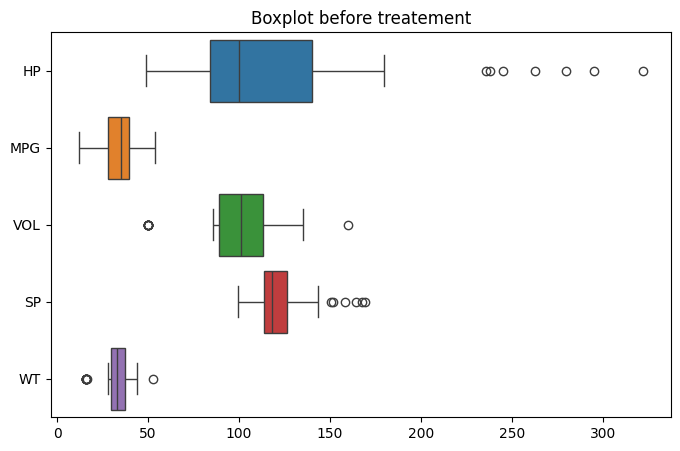

In [ ]:
plt.figure(figsize=(8,5))
sns.boxplot(data=cars,orient='h')
plt.title("Boxplot before treatement")
plt.show()

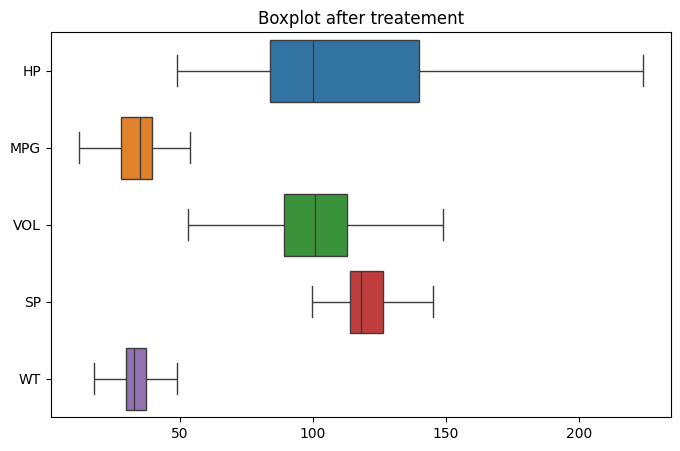

In [ ]:
winsor=Winsorizer(
    capping_method="iqr",
    tail="both",
    fold=1.5,
    variables=list(cars.columns)
)
cars = winsor.fit_transform(cars)

plt.figure(figsize=(8,5))
sns.boxplot(data=cars,orient='h')
plt.title("Boxplot after treatement")
plt.show()


In [ ]:
print("skewness:\n",cars.skew())

skewness:
 HP     1.066023
MPG   -0.177947
VOL   -0.609289
SP     0.742314
WT    -0.532006
dtype: float64


In [ ]:
#train test split
x=cars.drop(columns=["MPG"])
y=cars["MPG"]

x_train,x_test,y_train,y_test=train_test_split(
    x,y,test_size=0.2,random_state=42)

print("training shape:\n",x_train.shape)
print("testing shape:\n",x_test.shape)

training shape:
 (64, 4)
testing shape:
 (17, 4)


In [ ]:
#build MLR model
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf

cars_train=pd.concat([x_train,y_train],axis=1)
cars_test=pd.concat([x_test,y_test],axis=1)

In [ ]:
ml1=smf.ols(formula="MPG~HP+VOL+SP+WT",data=cars_train).fit()
print(ml1.summary())

                            OLS Regression Results                            
Dep. Variable:                    MPG   R-squared:                       0.831
Model:                            OLS   Adj. R-squared:                  0.820
Method:                 Least Squares   F-statistic:                     72.55
Date:                Thu, 04 Jun 2026   Prob (F-statistic):           4.23e-22
Time:                        11:39:31   Log-Likelihood:                -172.94
No. Observations:                  64   AIC:                             355.9
Df Residuals:                      59   BIC:                             366.7
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     23.8092     15.265      1.560      0.1

In [ ]:
#multicollinearity check(VIF)
rsq_hp=smf.ols(formula="HP~VOL+SP+WT",data=cars_train).fit().rsquared
vif_hp=1/(1-rsq_hp)

rsq_vol=smf.ols(formula="VOL~HP+SP+WT",data=cars_train).fit().rsquared
vif_vol=1/(1-rsq_vol)

rsq_sp=smf.ols(formula="SP~HP+VOL+WT",data=cars_train).fit().rsquared
vif_sp=1/(1-rsq_sp)

rsq_wt=smf.ols(formula="WT~HP+VOL+SP",data=cars_train).fit().rsquared
vif_wt=1/(1-rsq_wt)

vif_frame=pd.DataFrame({"vif":[vif_hp,vif_vol,vif_sp,vif_wt]},
                       index=["HP","VOL","SP","WT"])
print(vif_frame)

            vif
HP    14.346688
VOL  539.732710
SP    14.715786
WT   544.198344


In [ ]:
#drop high VIF variable
final_ml=smf.ols(formula="MPG~HP+VOL+SP",data=cars_train).fit()
print(final_ml.summary())

                            OLS Regression Results                            
Dep. Variable:                    MPG   R-squared:                       0.830
Model:                            OLS   Adj. R-squared:                  0.821
Method:                 Least Squares   F-statistic:                     97.60
Date:                Thu, 04 Jun 2026   Prob (F-statistic):           4.75e-23
Time:                        11:44:54   Log-Likelihood:                -173.15
No. Observations:                  64   AIC:                             354.3
Df Residuals:                      60   BIC:                             362.9
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     23.6815     15.186      1.559      0.1

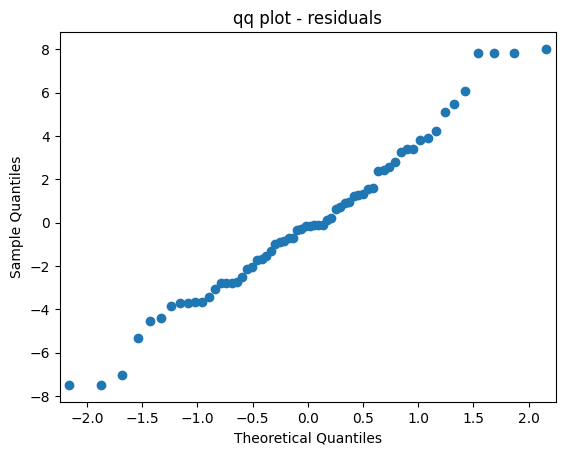

In [ ]:
#assumption checking
train_pred=final_ml.predict(cars_train)
test_pred=final_ml.predict(cars_test)

residuals=final_ml.resid


sm.qqplot(residuals)
plt.title("qq plot - residuals")
plt.show()

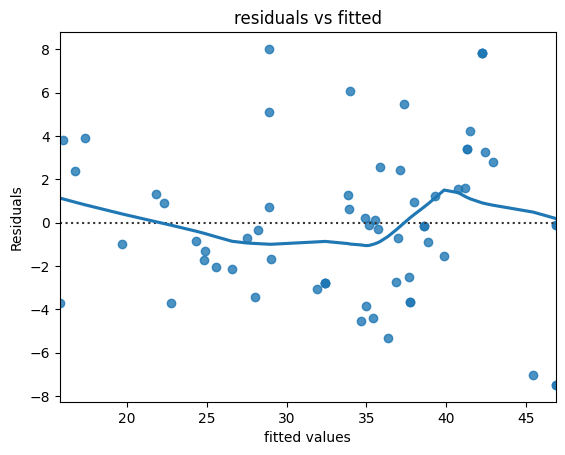

In [ ]:
sns.residplot(x=train_pred,y=y_train,lowess=True)
plt.xlabel("fitted values")
plt.ylabel("Residuals")
plt.title("residuals vs fitted")
plt.show()

In [ ]:
train_rmse=np.sqrt(np.mean((train_pred-y_train)**2))
test_rmse=np.sqrt(np.mean((test_pred-y_test)**2))
print("train rmse:",round(train_rmse,4))
print("test rmse:",round(test_rmse,4))



train rmse: 3.6204
test rmse: 4.494


In [ ]:
#final model summary
------------------------------------------------------------
#BUSINESS IMPACT
------------------------------------------------------------
'''1️ Strategic Impact:
Enables automobile manufacturers to design vehicles aligned with fuel-efficiency regulations and sustainability goals.
Supports long-term R&D strategy by identifying performance–efficiency trade-offs.
Strengthens competitive positioning in markets where fuel economy is a key purchase driver.

2️ Financial Impact:

Reduction in fuel consumption improves product attractiveness, leading to higher sales.
Optimized engine and vehicle design reduces material and manufacturing costs (weight optimization).
Minimizes regulatory penalties related to emission and fuel economy standards.
Improves ROI on product development by focusing investment on high-impact features.

3️ Operational Impact:

Assists engineering teams in data-driven vehicle design decisions.
Reduces trial-and-error experimentation during prototype development.
Supports simulation-based testing instead of expensive physical testing.
Enables faster product development cycles using predictive modeling.

4️ Regulatory & Environmental Impact:

Helps manufacturers meet government fuel efficiency and emission norms.
Contributes to lower carbon footprint and environmental sustainability.
Aligns with global climate goals and green mobility initiatives.

️⃣ 5 Customer & Market Impact:

Provides customers with more fuel-efficient and cost-effective vehicles.
Improves brand reputation as an environmentally responsible manufacturer.
Enables data-backed marketing claims (e.g., optimized MPG performance).
Helps customers make informed purchasing decisions based on efficiency metrics.

6️ Analytical & Organizational Impact:

Promotes adoption of data-driven decision-making in automotive engineering.
Builds internal analytics capability within product design teams.
Creates foundation for advanced modeling (non-linear regression, ML models).
Enables continuous performance monitoring and improvement.

7️ Long-Term Impact:

Supports transition toward hybrid and electric vehicle optimization strategies.
Provides scalable modeling framework for future vehicle platforms.
Establishes predictive intelligence in product lifecycle management.'''